# 01 — Point Operations: Brightness & Contrast

Công thức:
- Độ sáng: `g = clip(f + beta, 0, 255)`
- Độ tương phản: `g = clip(alpha * (f - 127.5) + 127.5, 0, 255)`

In [7]:
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

candidates = [
    Path("../data/input")
]

DATA_DIR = next(
    (p.resolve() for p in candidates if p.is_dir()),
    None
)

if DATA_DIR is None:
    raise FileNotFoundError(
        f"Không tìm thấy thư mục data/input. "
        f"Thư mục hiện tại: {Path.cwd()}"
    )

IMAGE_NAMES = [
    "02_chelsea.png",
    "03_coffee.png",
    "09_moon.png"
]

LAB_DIR = DATA_DIR.parent.parent
OUTPUT_DIR = LAB_DIR / "result" / "brightness_contrast_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

missing = [
    name for name in IMAGE_NAMES
    if not (DATA_DIR / name).is_file()
]

if missing:
    print("Không tìm thấy ảnh:", missing)
    print("Thư mục đang đọc:", DATA_DIR)
    print("Các file hiện có:")
    print(sorted(p.name for p in DATA_DIR.iterdir() if p.is_file()))
    raise FileNotFoundError("Hãy kiểm tra lại tên ảnh.")

images = {
    name: np.asarray(
        Image.open(DATA_DIR / name).convert("RGB"),
        dtype=np.float32
    )
    for name in IMAGE_NAMES
}

for name, image in images.items():
    print(f"{name}: kích thước = {image.shape}")

02_chelsea.png: kích thước = (300, 451, 3)
03_coffee.png: kích thước = (400, 600, 3)
09_moon.png: kích thước = (512, 512, 3)


In [8]:
def adjust_brightness(image, beta):
    """Cộng/trừ beta vào từng kênh pixel, sau đó clip về [0, 255]."""
    return np.clip(image + beta, 0, 255).astype(np.uint8)

def adjust_contrast(image, alpha):
    """Điều chỉnh tương phản quanh điểm giữa 127.5."""
    if alpha < 0:
        raise ValueError("alpha phải >= 0")
    return np.clip((image - 127.5) * alpha + 127.5, 0, 255).astype(np.uint8)

## 1. Tăng và giảm sáng

Chạy trên cả ba ảnh. Ảnh gốc và các mức beta được hiển thị cạnh nhau.

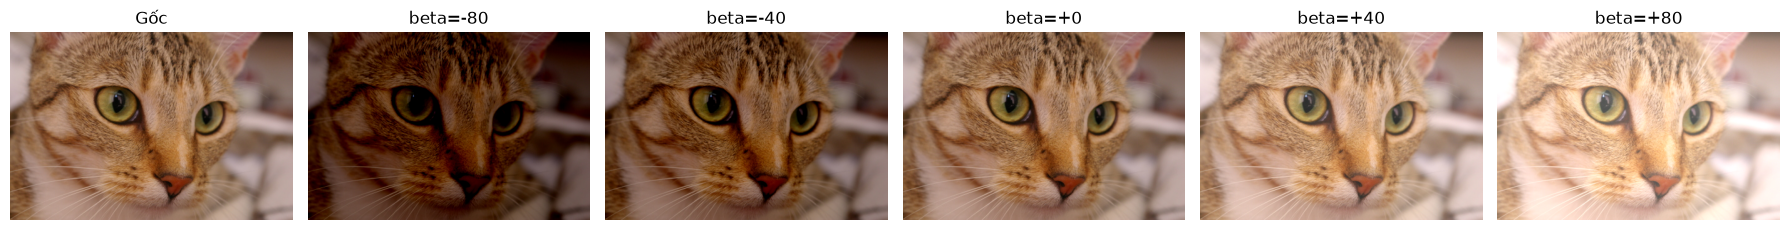

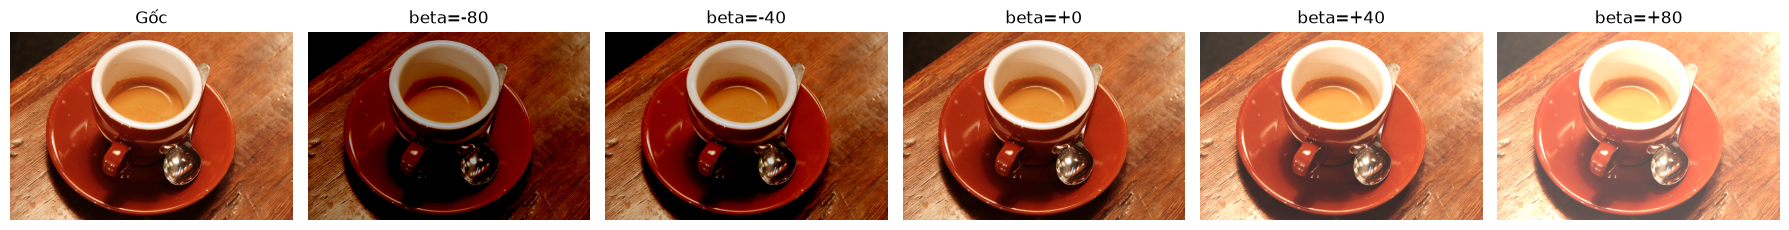

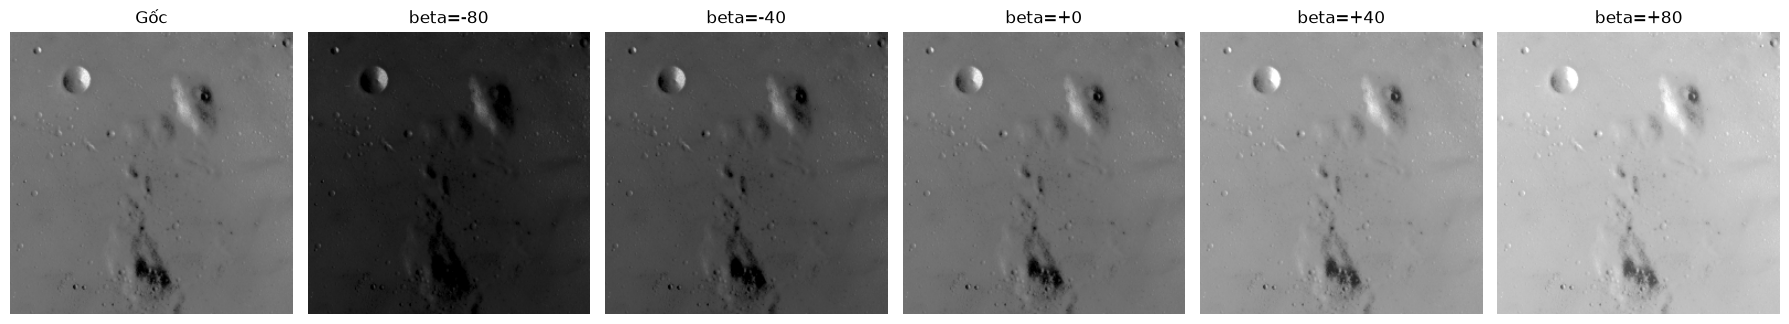

In [9]:
brightness_values = [-80, -40, 0, 40, 80]
for name, original in images.items():
    fig, axes = plt.subplots(1, len(brightness_values) + 1, figsize=(18, 4))
    axes[0].imshow(original.astype(np.uint8)); axes[0].set_title(f"Gốc")
    per_image_dir = OUTPUT_DIR / Path(name).stem
    per_image_dir.mkdir(parents=True, exist_ok=True)
    for ax, beta in zip(axes[1:], brightness_values):
        result = adjust_brightness(original, beta)
        ax.imshow(result); ax.set_title(f"beta={beta:+d}")
        Image.fromarray(result).save(per_image_dir / f"brightness_{beta:+d}.png")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()

## 2. Giảm và tăng tương phản

`alpha < 1` giảm tương phản, `alpha = 1` giữ nguyên, `alpha > 1` tăng tương phản.

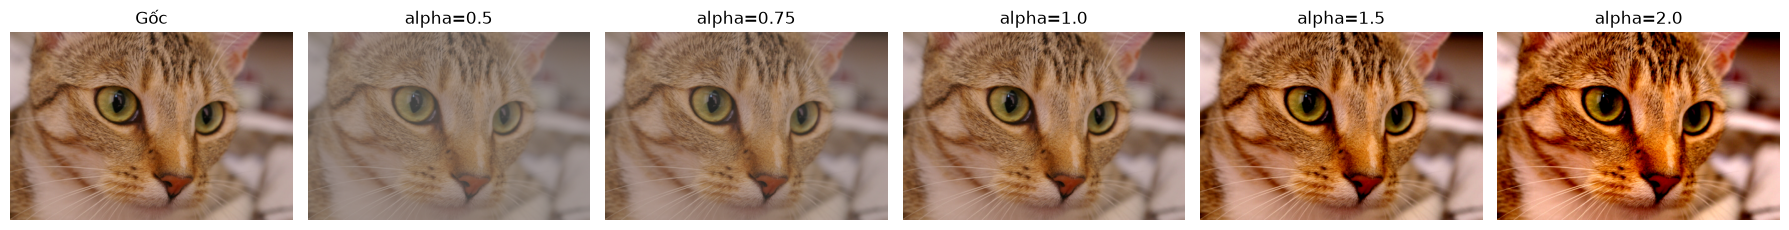

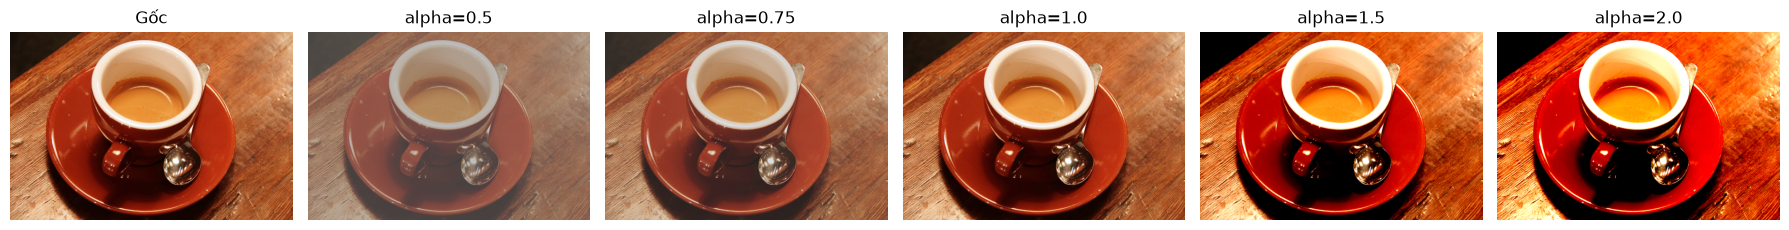

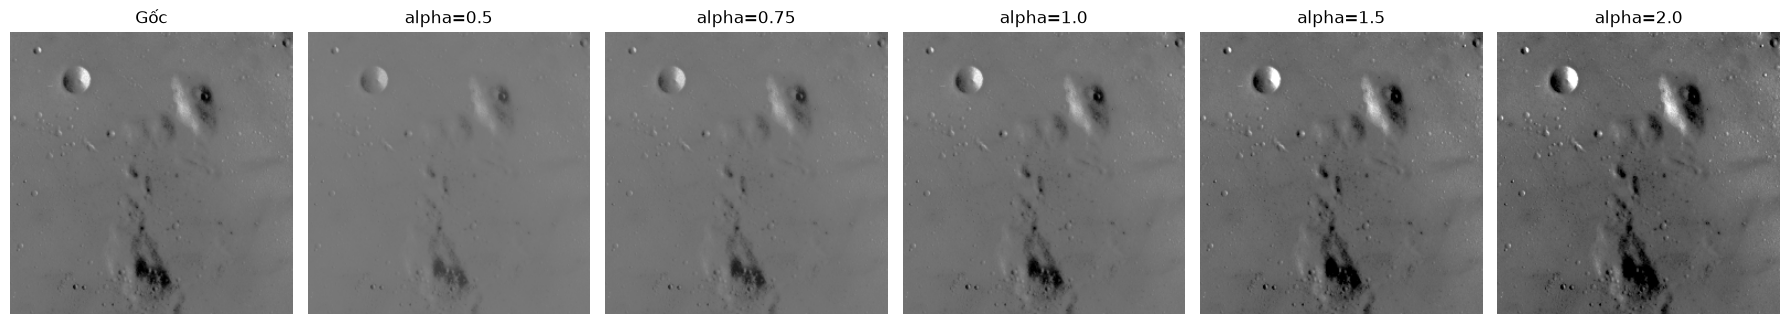

In [10]:
contrast_values = [0.5, 0.75, 1.0, 1.5, 2.0]
for name, original in images.items():
    fig, axes = plt.subplots(1, len(contrast_values) + 1, figsize=(18, 4))
    axes[0].imshow(original.astype(np.uint8)); axes[0].set_title(f"Gốc")
    per_image_dir = OUTPUT_DIR / Path(name).stem
    per_image_dir.mkdir(parents=True, exist_ok=True)
    for ax, alpha in zip(axes[1:], contrast_values):
        result = adjust_contrast(original, alpha)
        ax.imshow(result); ax.set_title(f"alpha={alpha}")
        Image.fromarray(result).save(per_image_dir / f"contrast_{alpha:.2f}.png")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()

## 3. Lưu ảnh so sánh cho từng ảnh đầu vào

Mỗi bảng gồm ảnh gốc, tăng sáng `+60`, giảm sáng `-60`, giảm tương phản `alpha=0.5`, tăng tương phản `alpha=1.5` và `alpha=2.0`.

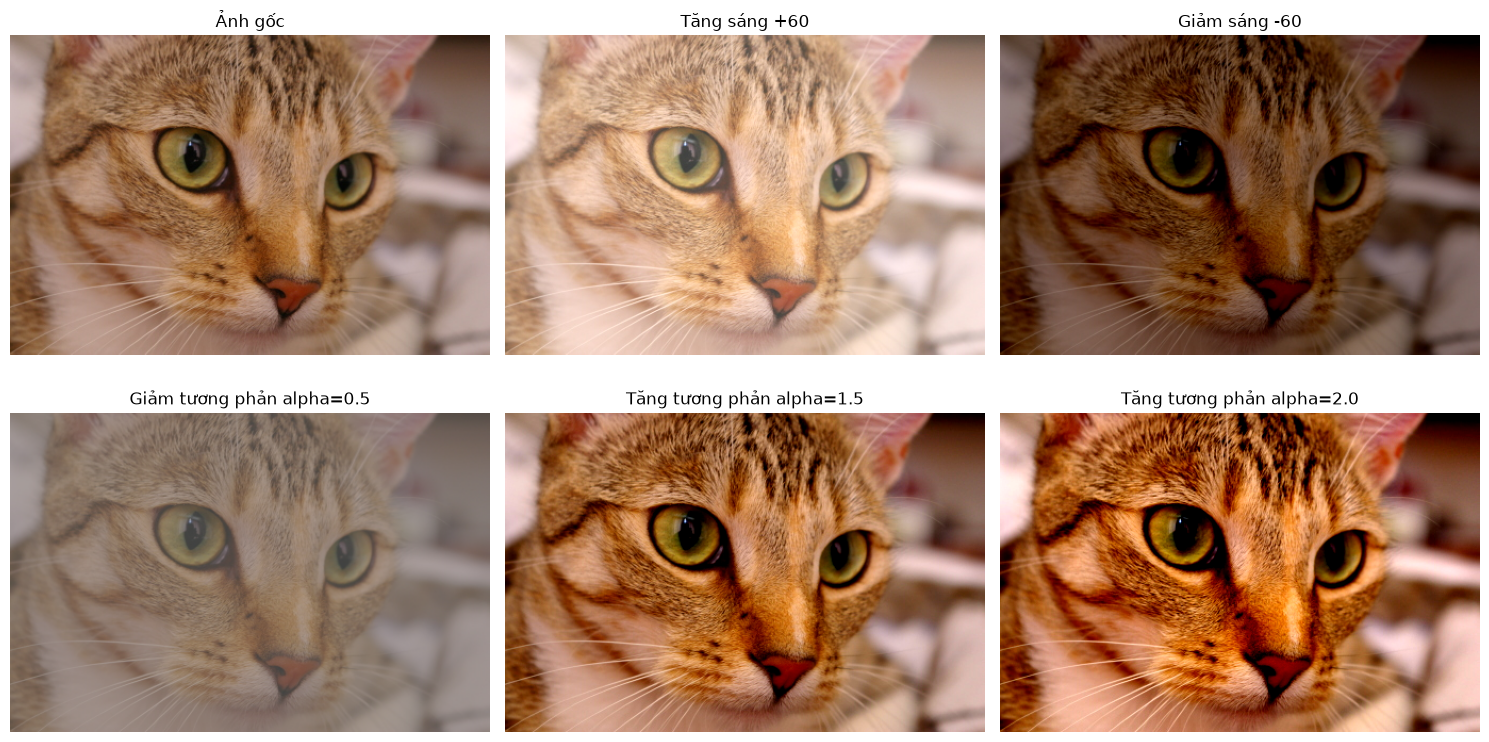

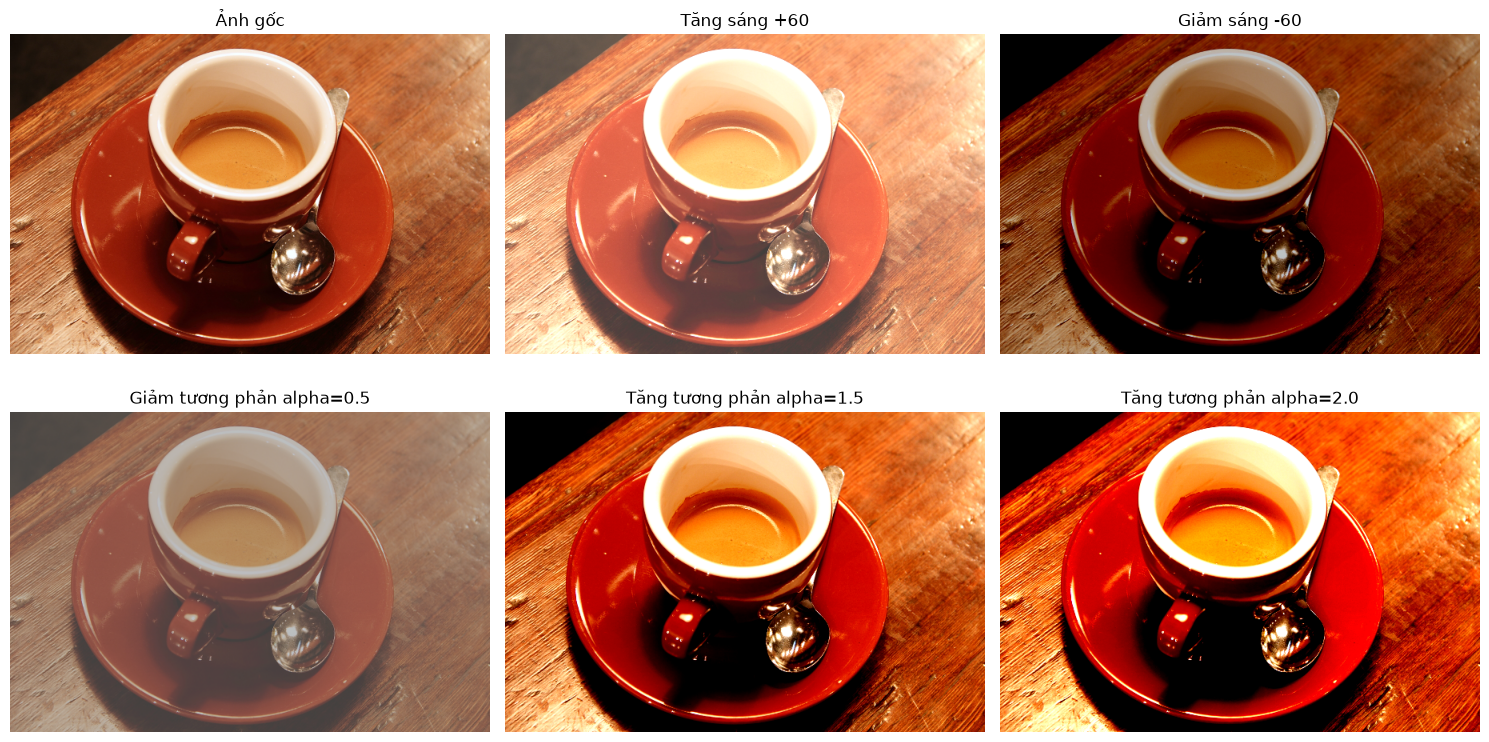

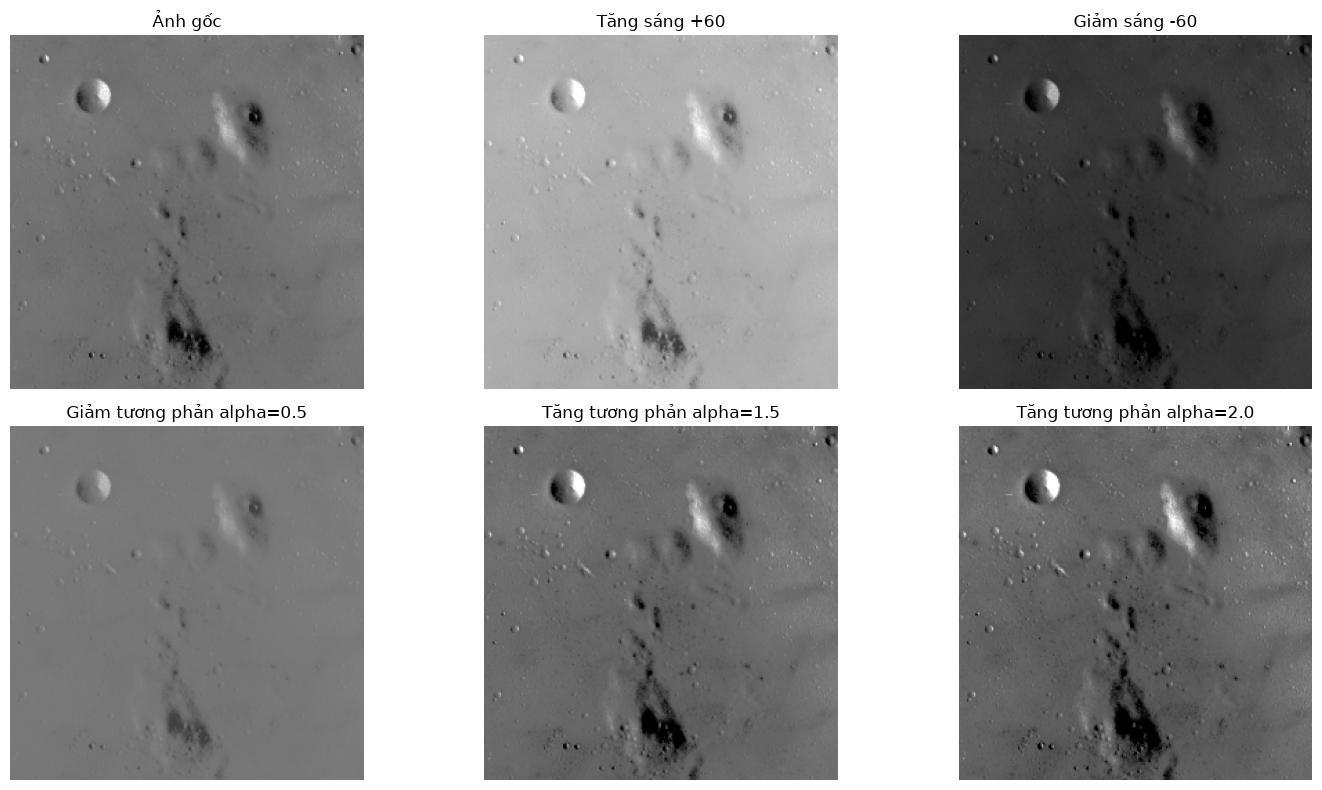

In [11]:
for name, original in images.items():
    samples = [
        ("Ảnh gốc", original.astype(np.uint8)),
        ("Tăng sáng +60", adjust_brightness(original, 60)),
        ("Giảm sáng -60", adjust_brightness(original, -60)),
        ("Giảm tương phản alpha=0.5", adjust_contrast(original, 0.5)),
        ("Tăng tương phản alpha=1.5", adjust_contrast(original, 1.5)),
        ("Tăng tương phản alpha=2.0", adjust_contrast(original, 2.0)),
    ]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, (title, result) in zip(axes.flat, samples):
        ax.imshow(result)
        ax.set_title(title)
        ax.axis("off")
    fig.tight_layout()
    per_image_dir = OUTPUT_DIR / Path(name).stem
    per_image_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(per_image_dir / "comparison_grid.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 4. Hiện tượng clipping

Với ảnh RGB 8-bit, mỗi kênh chỉ nhận giá trị từ 0 đến 255. Sau phép toán, `clip` giới hạn mọi giá trị nhỏ hơn 0 thành 0 và mọi giá trị lớn hơn 255 thành 255.

Ví dụ: `250 + 20 = 270` bị cắt thành `255`; `10 - 30 = -20` bị cắt thành `0`. Clipping có thể làm mất chi tiết vùng quá sáng hoặc quá tối, vì các giá trị ban đầu khác nhau đều bị dồn về cùng một mức biên.

In [12]:
samples = np.array([0, 10, 100, 200, 250], dtype=np.float32)
print("Pixel gốc:            ", samples.astype(int))
print("Cộng 30, chưa clipping:", (samples + 30).astype(int))
print("Cộng 30, có clipping:  ", np.clip(samples + 30, 0, 255).astype(int))
print("Trừ 30, chưa clipping: ", (samples - 30).astype(int))
print("Trừ 30, có clipping:   ", np.clip(samples - 30, 0, 255).astype(int))

Pixel gốc:             [  0  10 100 200 250]
Cộng 30, chưa clipping: [ 30  40 130 230 280]
Cộng 30, có clipping:   [ 30  40 130 230 255]
Trừ 30, chưa clipping:  [-30 -20  70 170 220]
Trừ 30, có clipping:    [  0   0  70 170 220]


## 5. Nhận xét

- Tăng sáng làm toàn ảnh sáng hơn; giảm sáng làm toàn ảnh tối hơn.
- Hệ số tương phản nhỏ hơn 1 kéo mức sáng gần điểm giữa, khiến ảnh ít tương phản. Hệ số lớn hơn 1 làm điểm ảnh sáng sáng hơn và điểm ảnh tối tối hơn.
- Tham số càng mạnh càng dễ xảy ra clipping; vùng bị dồn về 0 hoặc 255 có thể mất chi tiết.